# Dust attenuation

How to add dust to GALFORM magnitudes and luminosity functions, using GALFORM's own dust model.

Dust sits in each galaxy's gas disk. The amount depends on the gas mass, its metallicity and the disk size, and how much light it blocks depends on wavelength and on how the galaxy is tilted. `dust='lacey16'` uses the settings of Lacey et al. (2016), and the result matches the magnitudes GALFORM itself produces.

One part of GALFORM's model is left out: the extra dimming of stars younger than 1 Myr inside the clouds they formed in. It needs tables that are not in `galaxies.hdf5`, and it matters mostly in the far-UV.

GALFORM is not public, so galform_analysis does not contain its dust model: it runs the dust code of your own GALFORM checkout. Before running, set `GALFORM_DIR` to a GALFORM checkout you have built with CMake (the build is expected in `<checkout>/build`; otherwise also set `GALFORM_BUILD_DIR`). The first dust call compiles a small program against that build and caches it.

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import oh_mpl_paper

import galform_analysis
from galform_analysis import get_base_dir

oh_mpl_paper.setconfig("k.wang")

# Configure once per session:
# galform_analysis.set_base_dir('/cosma5/data/durham/<user>/Galform_Out/L800/model')
# os.environ['GALFORM_DIR'] = '/path/to/galform'   # your built GALFORM checkout
BASE_DIR = str(get_base_dir())
print('GALFORM_DIR set:', 'GALFORM_DIR' in os.environ)

GALFORM_DIR set: True


## How much light does dust remove?

`read_band_magnitudes` gives every galaxy's magnitude, with or without dust. The difference is the attenuation. Each galaxy gets a random orientation, the same in every band, so colours stay consistent.

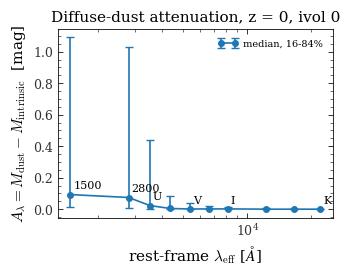

In [2]:
from galform_analysis import read_band_magnitudes

iz_path = os.path.join(BASE_DIR, 'iz271')
BANDS = ['TH1500', 'TH2800', 'U', 'B', 'V', 'R', 'I', 'UKIRT-J', 'UKIRT-H', 'UKIRT-K']
table = galform_analysis.list_bands(iz_path)

lam, median, lo, hi = [], [], [], []
for band in BANDS:
    bare = read_band_magnitudes(iz_path, 0, band)
    dusty = read_band_magnitudes(iz_path, 0, band, dust='lacey16')
    bright = bare['mag'] < -18          # galaxies with M - 5log h < -18
    a = (dusty['mag'] - bare['mag'])[bright]
    lam.append(table['lambda_eff'][bare['band_index'] - 1])
    p16, p50, p84 = np.percentile(a, [16, 50, 84])
    median.append(p50); lo.append(p50 - p16); hi.append(p84 - p50)

fig, ax = plt.subplots()
ax.errorbar(lam, median, yerr=[lo, hi], fmt='o-', ms=4, capsize=3,
            label='median, 16-84%')
# Label a few bands only: the plot is one MNRAS column wide.
SHORT = {'TH1500': '1500', 'TH2800': '2800', 'U': 'U', 'V': 'V', 'I': 'I', 'UKIRT-K': 'K'}
for x, y, band in zip(lam, median, BANDS):
    if band in SHORT:
        ax.annotate(SHORT[band], (x, y), textcoords='offset points', xytext=(2, 4))
ax.set_xscale('log')
ax.set_xlabel(r'rest-frame $\lambda_{\rm eff}$ [$\AA$]')
ax.set_ylabel(r'$A_\lambda = M_{\rm dust} - M_{\rm intrinsic}$  [mag]')
ax.set_title('Diffuse-dust attenuation, z = 0, ivol 0')
ax.legend()
plt.show()

## Inclination

Edge-on disks lose the most light. `inclination` can be `'random'` (the default), `'face-on'`, `'average'` (the mean over all orientations) or an angle in degrees.

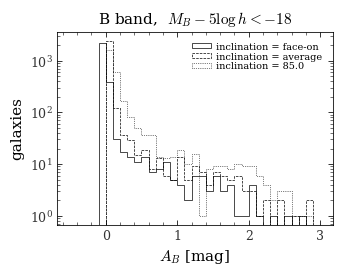

In [3]:
fig, ax = plt.subplots()
bare = read_band_magnitudes(iz_path, 0, 'B')['mag']
bright = bare < -18
bins = np.linspace(-0.5, 3.0, 36)
for inc, style in (('face-on', '-'), ('average', '--'), (85.0, ':')):
    a = read_band_magnitudes(iz_path, 0, 'B', dust='lacey16', inclination=inc)['mag'] - bare
    ax.hist(a[bright], bins=bins, histtype='step', ls=style, color='k',
            label=f'inclination = {inc}')
ax.set_yscale('log')
ax.set_xlabel(r'$A_B$ [mag]')
ax.set_ylabel('galaxies')
ax.set_title(r'B band,  $M_B - 5\log h < -18$')
ax.legend()
plt.show()

## Luminosity functions with dust

All the luminosity function functions take `dust=`, `inclination=` and `seed=`. Dust matters most in blue bands. Here the model is compared with 2dFGRS in bJ (Norberg et al. 2002) and 2MASS in K (Cole et al. 2001). Both fits are in Vega magnitudes, drawn only over the range they were measured.

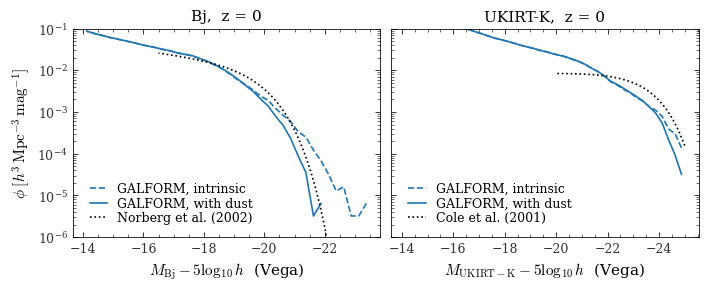

In [4]:
from galform_analysis.analysis.luminosity_functions import (
    avg_lf_given_redshift_and_subvolumes,
    schechter_magnitude,
)

IVOLS = list(range(8))
OBSERVED = {   # band: (phi*, M* - 5log h, alpha, fitted range, reference)
    'Bj': (1.61e-2, -19.66, -1.21, (-22.5, -16.5), 'Norberg et al. (2002)'),
    'UKIRT-K': (1.08e-2, -23.44, -0.96, (-25.0, -20.0), 'Cole et al. (2001)'),
}

fig, axes = plt.subplots(1, 2, figsize=(6.97, 2.8), sharey=True)
for ax, (band, (phi_star, m_star, alpha, (m_lo, m_hi), ref)) in zip(
        axes, OBSERVED.items()):
    for dust, style in ((None, 'C0--'), ('lacey16', 'C0-')):
        r = avg_lf_given_redshift_and_subvolumes(271, IVOLS, band, system='Vega',
                                                 dust=dust, base_dir=BASE_DIR)
        ok = r['phi'] > 0   # empty bins cannot be drawn on a log axis
        label = 'GALFORM, intrinsic' if dust is None else 'GALFORM, with dust'
        ax.plot(r['centers'][ok], r['phi'][ok], style, label=label)
    M = np.linspace(m_lo, m_hi, 200)
    ax.plot(M, schechter_magnitude(M, phi_star, m_star, alpha), 'k:', label=ref)
    ax.set_yscale('log')
    ax.set_ylim(1e-6, 1e-1)
    ax.invert_xaxis()
    ax.set_xlabel(rf'$M_{{\rm {band}}} - 5\log_{{10}}h$  (Vega)')
    ax.set_title(f'{band},  z = 0')
    ax.legend(fontsize=9)
axes[0].set_ylabel(r'$\phi\;[h^3\,\mathrm{Mpc}^{-3}\,\mathrm{mag}^{-1}]$')
plt.show()

## Other dust settings

`'baugh05'` uses the settings of Baugh et al. (2005). For anything else, make a `DustModel`. Its `table` can also be the path to any GALFORM `dust_*.dat` file.

In [5]:
import dataclasses
from galform_analysis.dust import DUST_MODELS, LACEY16

print(DUST_MODELS)
no_bursts = dataclasses.replace(LACEY16, name='lacey16-nobursts', rfacburst=0.0)
r = avg_lf_given_redshift_and_subvolumes(271, [0], 'Bj', dust=no_bursts, base_dir=BASE_DIR)
print(r['dust'], r['n_used'])

{'lacey16': DustModel(name='lacey16', table='dust_MW_hz1.0.dat', fcloud=0.5, rfacburst=1.0), 'baugh05': DustModel(name='baugh05', table='dust_MW_hz1.0.dat', fcloud=0.25, rfacburst=1.0)}
lacey16-nobursts 1
